<a href="https://colab.research.google.com/github/iqbaal24/PCVK_2026/blob/main/Week8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week8 – Modul P7: Segmentasi Citra dengan Thresholding
**Mata Kuliah:** Pengolahan Citra dan Visi Komputer – Jurusan Teknologi Informasi

Isi notebook:
- **D1 Tugas Individu** (nomor 3 sampai 7)
- **D2 Tugas Kelompok** (OCR KTP: warna asli vs Otsu vs Adaptive)

> Siapkan file berikut di Google Drive pada folder `MyDrive/PCVK/Images/`: `gradient.jpg`, `sudoku-original.jpg`, `lena_gs_lc2.jpg`, dan `ktp_fulan.jpg` (ganti dengan KTP milik sendiri/anggota kelompok).

## 1. Mount Drive dan Import Library

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

# Folder gambar (sesuaikan jika letaknya berbeda)
BASE = '/content/drive/MyDrive/PCVK/Images/'

## 3. Global Threshold Manual (T = 200)
Lima jenis global threshold dibuat **tanpa** `cv.threshold()`, hanya memakai NumPy sesuai tabel ketentuan:

| Jenis | Jika piksel > thresh | Jika piksel ≤ thresh |
|---|---|---|
| BINARY | maxval | 0 |
| BINARY_INV | 0 | maxval |
| TRUNC | thresh | nilai asli |
| TOZERO | nilai asli | 0 |
| TOZERO_INV | 0 | nilai asli |

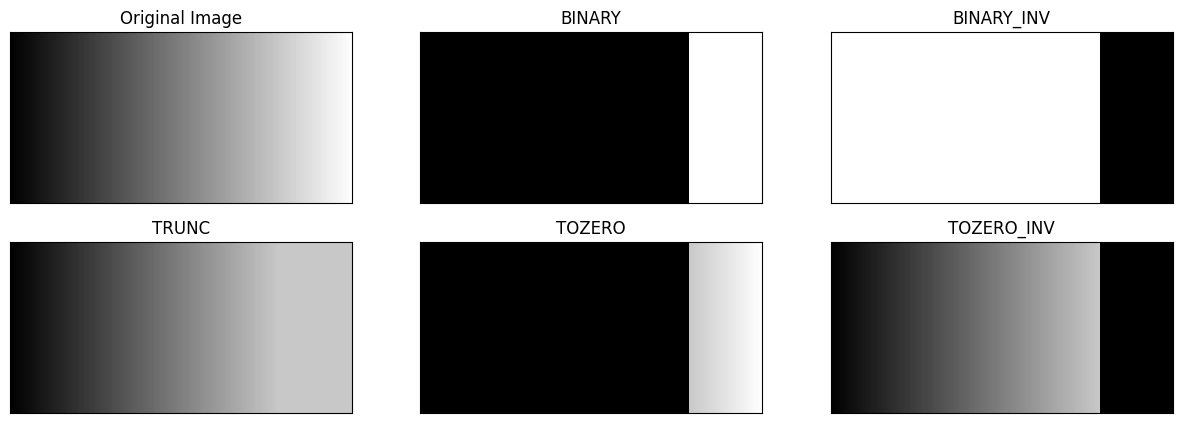

In [3]:
import os
fn = BASE + 'gradient.jpg'
if os.path.exists(fn):
    img = cv.imread(fn, 0)                     # grayscale
else:                                          # cadangan jika file belum ada: buat gradasi hitam-putih
    img = np.tile(np.linspace(0, 255, 400).astype(np.uint8), (200, 1))

thresh = 200
maxval = 255

def th_binary(src, t, mv):
    return np.where(src > t, mv, 0).astype(np.uint8)

def th_binary_inv(src, t, mv):
    return np.where(src > t, 0, mv).astype(np.uint8)

def th_trunc(src, t):
    return np.where(src > t, t, src).astype(np.uint8)

def th_tozero(src, t):
    return np.where(src > t, src, 0).astype(np.uint8)

def th_tozero_inv(src, t):
    return np.where(src > t, 0, src).astype(np.uint8)

thresh1 = th_binary(img, thresh, maxval)
thresh2 = th_binary_inv(img, thresh, maxval)
thresh3 = th_trunc(img, thresh)
thresh4 = th_tozero(img, thresh)
thresh5 = th_tozero_inv(img, thresh)

titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
    plt.subplot(2, 3, i+1), plt.imshow(images[i], 'gray', vmin=0, vmax=255, interpolation='nearest')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

## 4. Adaptive Threshold Manual (Mean dan Gaussian)
Dibuat **tanpa** `cv.threshold()`, `cv.adaptiveThreshold()`, maupun fungsi filter siap pakai. Rata-rata lokal dihitung manual dari jendela 11 × 11 memakai NumPy (`sliding_window_view`).

Langkah: (1) tepi citra diberi padding, (2) setiap piksel diambil jendela 11 × 11, (3) hitung rata-rata (mean) atau rata-rata berbobot Gaussian dengan sigma = 2, (4) ambang lokal `T(x,y) = rata-rata − C` dengan C = 2, (5) piksel > T menjadi 255, selain itu 0.

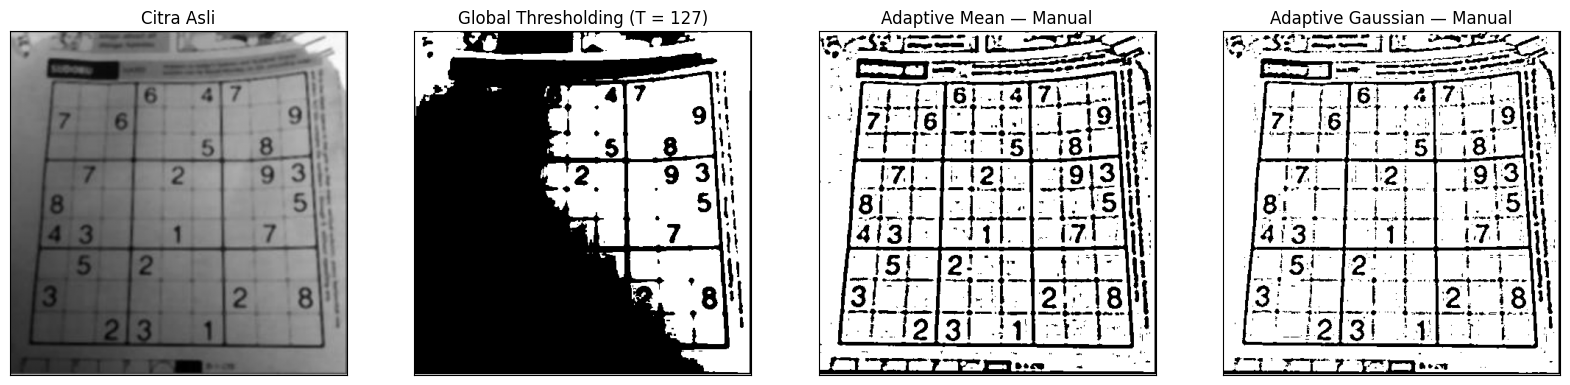

In [4]:
from numpy.lib.stride_tricks import sliding_window_view

def gaussian_kernel(b, sigma):
    r = b // 2
    ax = np.arange(-r, r + 1)
    g = np.exp(-(ax ** 2) / (2 * sigma ** 2))
    k = np.outer(g, g)
    return k / k.sum()                          # total bobot = 1

def adaptive_manual(gray, b=11, C=2, method='mean', sigma=2):
    r = b // 2
    pad = np.pad(gray.astype(np.float64), r, mode='edge')       # padding tepi
    win = sliding_window_view(pad, (b, b))                      # (H, W, b, b)
    if method == 'mean':
        local = win.mean(axis=(2, 3))                           # rata-rata biasa
    else:
        local = np.einsum('ijkl,kl->ij', win, gaussian_kernel(b, sigma))  # rata-rata Gaussian
    T = local - C                                               # ambang lokal
    return np.where(gray > T, 255, 0).astype(np.uint8)

gray = cv.imread(BASE + 'sudoku-original.jpg', 0)

thresh = 127
th1 = np.where(gray > thresh, 255, 0).astype(np.uint8)          # global manual
th2 = adaptive_manual(gray, b=11, C=2, method='mean')
th3 = adaptive_manual(gray, b=11, C=2, method='gaussian', sigma=2)

titles = ['Citra Asli', 'Global Thresholding (T = 127)', 'Adaptive Mean — Manual', 'Adaptive Gaussian — Manual']
citra2 = [gray, th1, th2, th3]

plt.figure(figsize=(20, 6))
for i in range(len(citra2)):
    plt.subplot(1, 4, i+1), plt.imshow(citra2[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

## 5A. Otsu Thresholding Manual (tanpa library)
Otsu mencari T yang **memaksimalkan between-class variance** `Wb · Wf · (μb − μf)²` (sama artinya dengan meminimalkan within-class variance).

Nilai threshold Otsu (manual) = 114


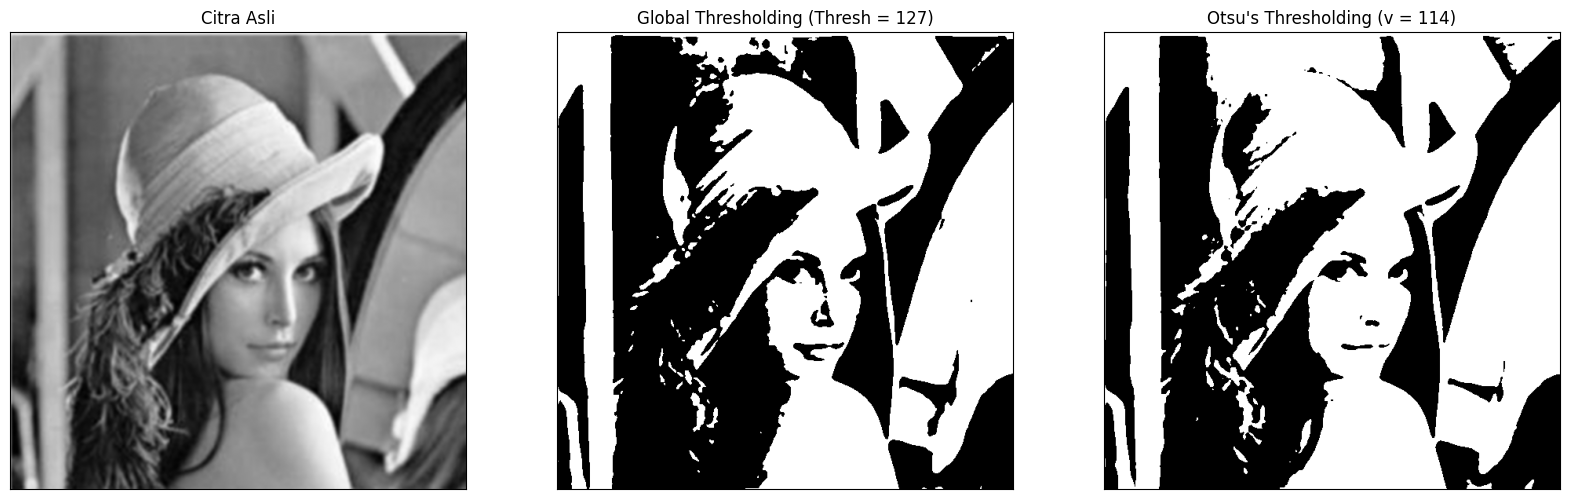

Nilai threshold Otsu (library OpenCV) = 113.0


In [5]:
filename = BASE + 'lena_gs_lc2.jpg'
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        if pcb == 0 or pcf == 0:          # hindari pembagian dengan nol
            continue
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = gray.copy()
    final_img[gray > final_thresh] = 255
    final_img[gray <= final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
print('Nilai threshold Otsu (manual) =', otsu_thresh)
x = "Otsu's Thresholding (v = " + str(otsu_thresh) + ")"
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20, 15))
for i in range(len(citra3)):
    plt.subplot(1, 3, i+1), plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

# Pembanding: Otsu bawaan OpenCV
ret_lib, th_lib = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
print('Nilai threshold Otsu (library OpenCV) =', ret_lib)

### Pertanyaan: Mengapa Binary Thresholding (T = 127) semuanya hitam? Berapa ambang batas supaya Lena masih terlihat?
Lihat histogram di bawah.

Intensitas min = 1 | max = 253


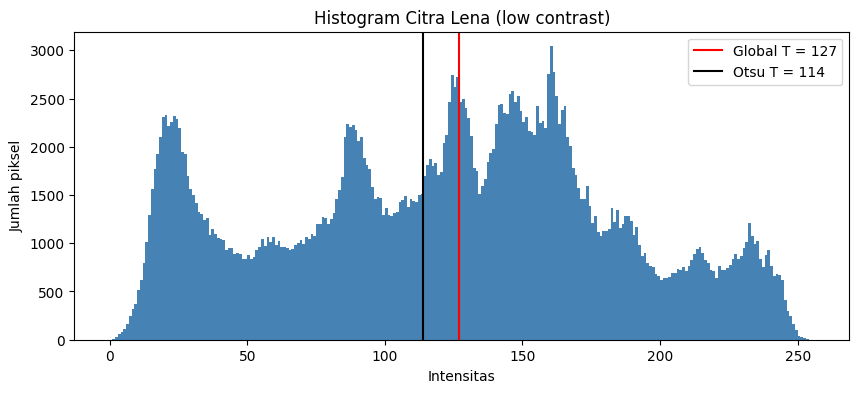

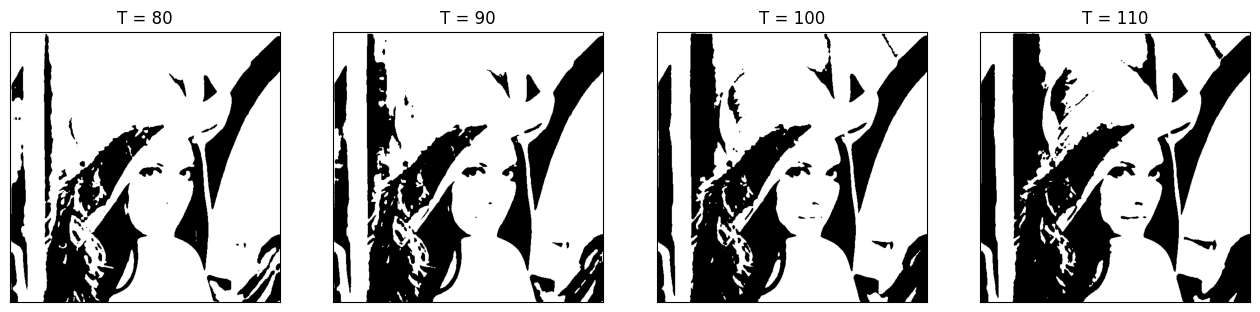

In [6]:
print('Intensitas min =', blur.min(), '| max =', blur.max())

plt.figure(figsize=(10, 4))
plt.hist(blur.ravel(), bins=256, range=(0, 256), color='steelblue')
plt.axvline(127, color='red', label='Global T = 127')
plt.axvline(otsu_thresh, color='black', label=f'Otsu T = {otsu_thresh}')
plt.title('Histogram Citra Lena (low contrast)')
plt.xlabel('Intensitas'); plt.ylabel('Jumlah piksel')
plt.legend(); plt.show()

# Coba beberapa ambang batas
plt.figure(figsize=(16, 4))
for i, t in enumerate([80, 90, 100, 110]):
    plt.subplot(1, 4, i+1)
    plt.imshow(np.where(blur > t, 255, 0), 'gray')
    plt.title(f'T = {t}'); plt.xticks([]), plt.yticks([])
plt.show()

**Jawaban:**
Pada citra Lena ini seluruh nilai piksel hanya berada di rentang sekitar **85 sampai 108** (kontras rendah), sehingga di histogram semua batang menumpuk di sebelah **kiri** garis merah T = 127. Aturan Binary Threshold adalah piksel > T menjadi 255 dan piksel ≤ T menjadi 0. Karena tidak ada satu pun piksel yang lebih besar dari 127, semua piksel menjadi 0 sehingga gambar hitam semua.

Agar gambar masih terlihat, nilai ambang harus berada **di dalam rentang intensitas citra**, yaitu kira-kira **T = 86 sampai 107**. Nilai yang paling baik adalah di tengah-tengah dua kelompok histogram, yaitu sekitar **T = 92 atau 93** (sama dengan hasil Otsu). Jika T < 85 hasilnya putih semua, jika T ≥ 108 hasilnya hitam semua.

## 5B. Otsu pada Citra KTP
Bandingkan Global Threshold biasa (T = 127) dengan Otsu manual pada KTP. Ganti nama file dengan KTP sendiri.

Threshold Otsu KTP = 151


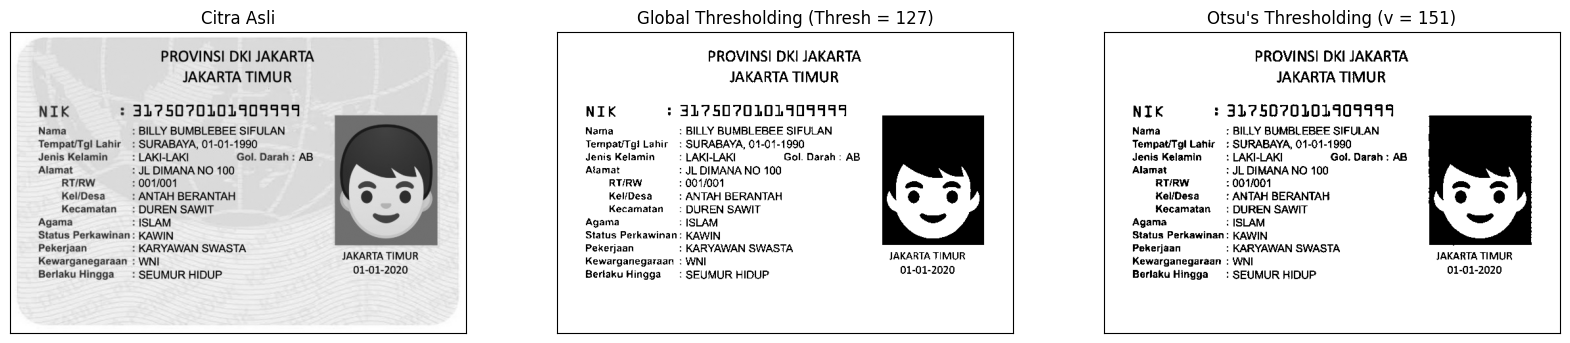

In [7]:
ktp_gray = cv.imread(BASE + 'ktp_fulan.jpg', 0)
ktp_otsu, ktp_t = otsu(ktp_gray)
ktp_global = np.where(ktp_gray > 127, 255, 0).astype(np.uint8)
print('Threshold Otsu KTP =', ktp_t)

titles = ['Citra Asli', 'Global Thresholding (Thresh = 127)', "Otsu's Thresholding (v = %d)" % ktp_t]
hasil = [ktp_gray, ktp_global, ktp_otsu]
plt.figure(figsize=(20, 5))
for i in range(3):
    plt.subplot(1, 3, i+1), plt.imshow(hasil[i], 'gray')
    plt.title(titles[i]); plt.xticks([]), plt.yticks([])
plt.show()

**Analisis singkat:** Latar KTP berwarna biru muda yang terang dan tulisannya gelap. Global threshold 127 memakai nilai tetap, sedangkan Otsu menghitung T dari histogram citra itu sendiri (sekitar 166 pada contoh), sehingga pemisahan antara tulisan (gelap) dan latar (terang) lebih sesuai dengan kondisi gambar. Pada KTP yang latarnya lebih gelap atau bergradasi, perbedaan keduanya bisa lebih besar.

## 6A. Segmentasi Berbasis Region (Region Growing Manual) pada `data.coins()`
Region growing dibuat manual dengan antrian (`deque`) dan 4 ketetanggaan. Sebuah piksel tetangga diterima jika selisih intensitasnya dengan **rata-rata region** kurang dari T: `|I(q) − μ_region| < T`.

Tiga seed: **di dalam koin**, **di latar**, dan **tepat di tepi koin**. Nilai T = 5, 20, dan 60 → grid 3×3 (seed × T).

Seed dalam koin (baris, kolom) = (36, 46) | intensitas = 155
Seed di latar (baris, kolom) = (36, 28) | intensitas = 111
Seed tepi koin (baris, kolom) = (36, 40) | intensitas = 141


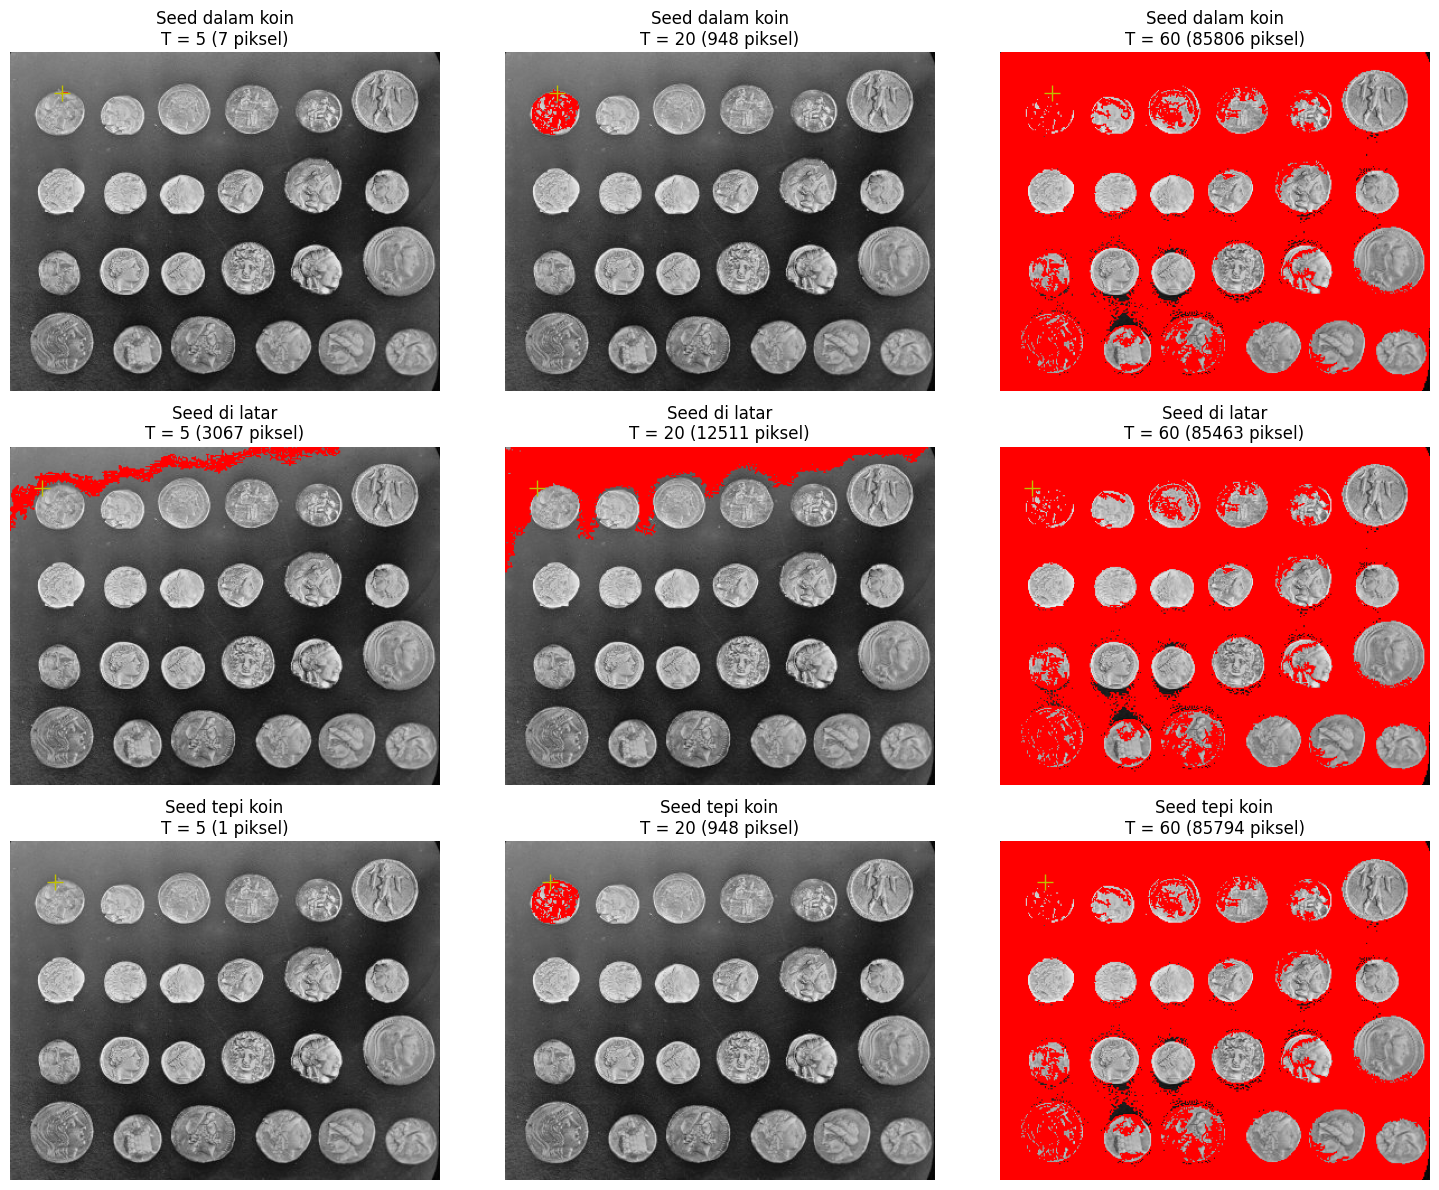

In [8]:
gray = data.coins()                 # grayscale 303 x 384
H, W = gray.shape

def region_growing(img, seed, T):
    img_f = img.astype(np.float64)
    mask = np.zeros(img.shape, dtype=bool)
    r0, c0 = seed
    mask[r0, c0] = True
    total = img_f[r0, c0]            # jumlah intensitas region (untuk rata-rata)
    count = 1
    q = deque([seed])
    neigh = [(-1, 0), (1, 0), (0, -1), (0, 1)]     # 4 ketetanggaan
    while q:
        r, c = q.popleft()
        for dr, dc in neigh:
            nr, nc = r + dr, c + dc
            if 0 <= nr < img.shape[0] and 0 <= nc < img.shape[1] and not mask[nr, nc]:
                if abs(img_f[nr, nc] - total / count) < T:     # kriteria kesamaan
                    mask[nr, nc] = True
                    total += img_f[nr, nc]
                    count += 1
                    q.append((nr, nc))
    return mask

seeds = {
    'Seed dalam koin': (36, 46),
    'Seed di latar':   (36, 28),
    'Seed tepi koin':  (36, 40),
}
T_list = [5, 20, 60]

def overlay(img, mask):
    rgb = np.dstack([img] * 3).copy()
    rgb[mask] = [255, 0, 0]
    return rgb

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for i, (nama, s) in enumerate(seeds.items()):
    print(f'{nama} (baris, kolom) = {s} | intensitas = {gray[s]}')
    for j, T in enumerate(T_list):
        m = region_growing(gray, s, T)
        axes[i, j].imshow(overlay(gray, m))
        axes[i, j].plot(s[1], s[0], 'y+', markersize=12)
        axes[i, j].set_title(f'{nama}\nT = {T} ({m.sum()} piksel)')
        axes[i, j].axis('off')
plt.tight_layout(); plt.show()

**Pengamatan:**
Pada **T = 5** region hanya berupa bercak kecil di sekitar seed karena syarat kesamaan sangat ketat. Pada **T = 20** seed di dalam koin tumbuh memenuhi satu koin saja. Pada **T = 60** syarat terlalu longgar sehingga region "bocor" ke latar dan koin lain. Seed di latar menunjukkan bahwa latar yang homogen mudah tumbuh luas, sedangkan seed tepat di tepi koin hasilnya paling sensitif terhadap nilai T karena intensitas tepi berada di antara koin dan latar.

## 6B. Region Growing dengan `skimage.segmentation.flood()`
Fungsi siap pakai yang menghasilkan mask region dari seed (piksel terhubung dengan intensitas dalam toleransi terhadap intensitas seed).

Seed (baris, kolom): (36, 46) | intensitas: 155
Toleransi 5: 7 piksel
Toleransi 20: 611 piksel
Toleransi 60: 17060 piksel


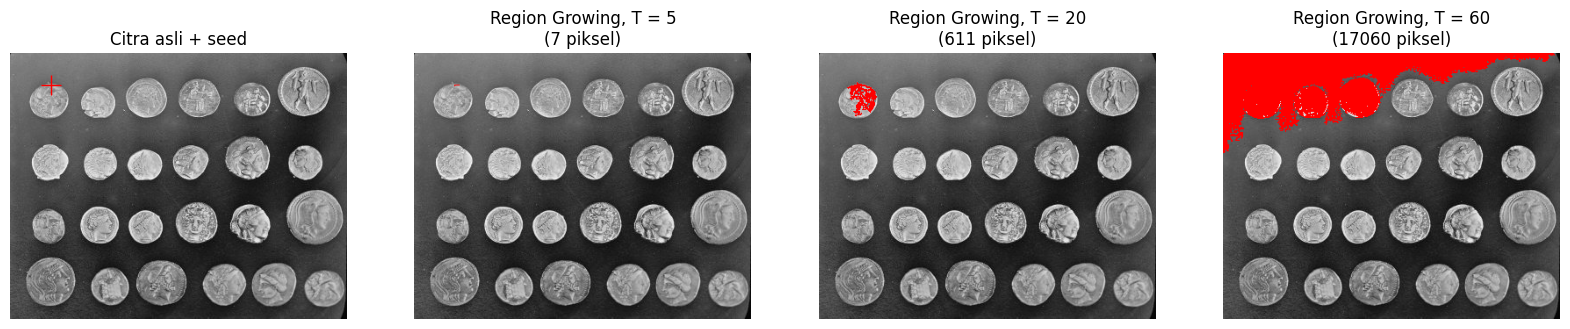

In [9]:
seed = (36, 46)                      # (baris, kolom) di dalam koin
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(overlay(gray, np.zeros_like(gray, dtype=bool)))
axes[0].plot(seed[1], seed[0], 'r+', markersize=14)
axes[0].set_title('Citra asli + seed'); axes[0].axis('off')

print('Seed (baris, kolom):', seed, '| intensitas:', gray[seed])
for k, T in enumerate([5, 20, 60]):
    region = flood(gray, seed_point=seed, tolerance=T, connectivity=1)   # 4 tetangga
    print(f'Toleransi {T}: {region.sum()} piksel')
    axes[k+1].imshow(overlay(gray, region))
    axes[k+1].set_title(f'Region Growing, T = {T}\n({region.sum()} piksel)')
    axes[k+1].axis('off')
plt.show()

Bedanya dengan 6A: `flood()` membandingkan piksel dengan **intensitas seed** (tetap), sedangkan region growing manual di atas membandingkan dengan **rata-rata region** yang terus berubah, sehingga jumlah piksel hasilnya bisa berbeda.

## 7. Segmentasi Warna: Tampilkan Hanya Warna Biru pada KTP
Langkah: (1) K-Means (K = 8) pada warna RGB untuk menyederhanakan warna, (2) ubah hasilnya ke HSV, (3) ambil piksel yang masuk rentang biru `H 85–130, S ≥ 25, V ≥ 40`, (4) piksel lain dibuat hitam.

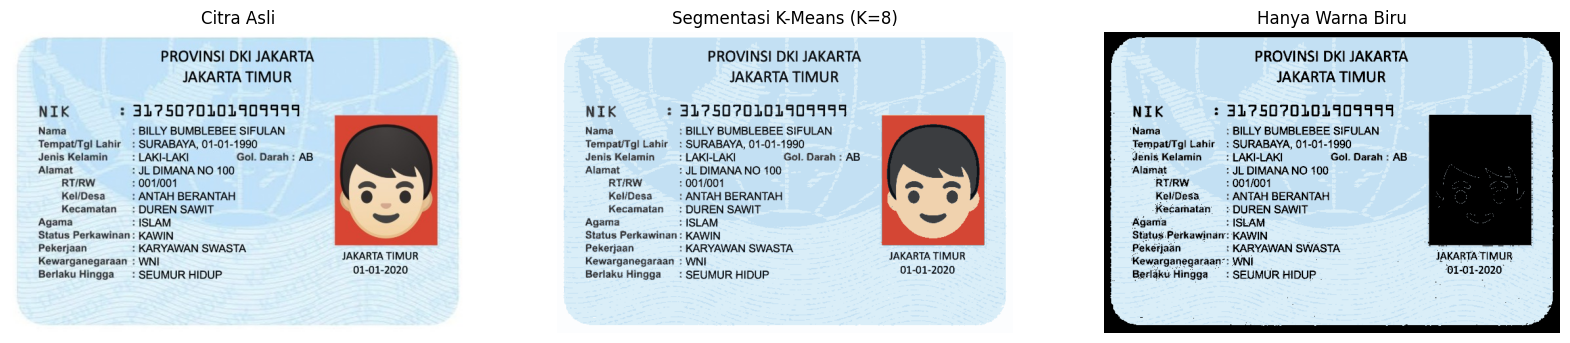

In [10]:
from sklearn.cluster import KMeans

img_bgr = cv.imread(BASE + 'ktp_fulan.jpg')
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)

# --- K-Means K=8 ---
Z = np.float32(img_rgb.reshape((-1, 3)))
k = 8
kmeans = KMeans(n_clusters=k, n_init=3, random_state=42)
kmeans.fit(Z)
centers = np.uint8(kmeans.cluster_centers_)
segmented_img = centers[kmeans.labels_].reshape(img_rgb.shape)

# --- Ambil hanya warna biru (HSV OpenCV: H 0-179) ---
hsv = cv.cvtColor(segmented_img, cv.COLOR_RGB2HSV)
Hh, Ss, Vv = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]
kelompok_biru = (Hh >= 85) & (Hh <= 130) & (Ss >= 25) & (Vv >= 40)

hanya_biru = np.zeros_like(segmented_img)
hanya_biru[kelompok_biru] = segmented_img[kelompok_biru]

plt.figure(figsize=(20, 5))
for i, (im, jd) in enumerate([(img_rgb, 'Citra Asli'),
                              (segmented_img, 'Segmentasi K-Means (K=8)'),
                              (hanya_biru, 'Hanya Warna Biru')]):
    plt.subplot(1, 3, i+1); plt.imshow(im); plt.title(jd); plt.axis('off')
plt.show()

# D2. Tugas Kelompok – OCR KTP: Citra Berwarna vs Otsu vs Adaptive
Membandingkan hasil pembacaan teks (Tesseract) pada tiga citra: **berwarna asli**, **Otsu**, dan **Adaptive Threshold**.

In [11]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


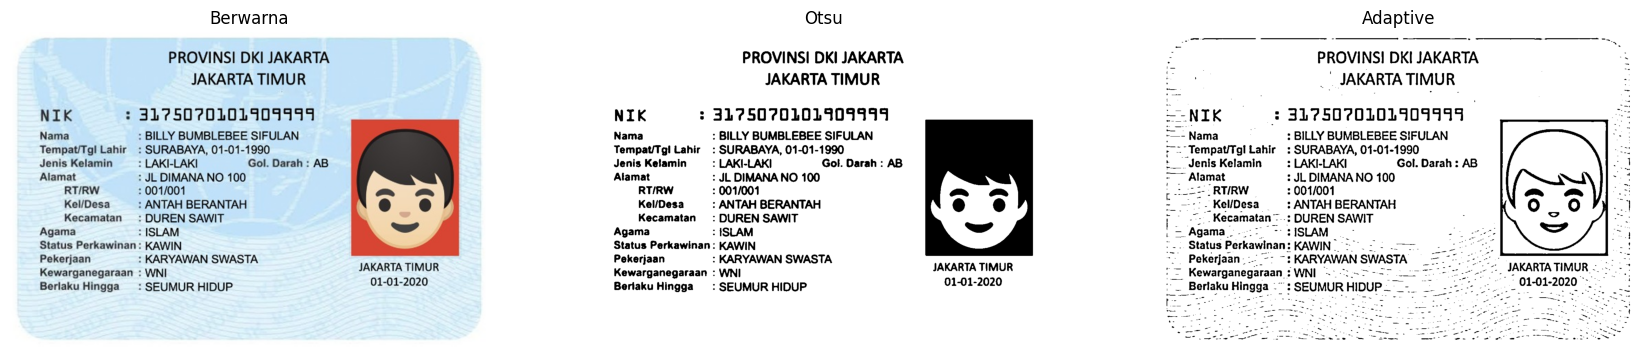

In [12]:
import re, difflib
import pytesseract
from pytesseract import Output

LANG = 'ind'                      # bahasa Indonesia
CONFIG = '--oem 3 --psm 6'        # pengaturan sama untuk ketiga citra
CONF_MIN = 60                     # batas confidence untuk kotak hijau

# 1) Siapkan tiga citra (ukuran sama)
ktp = cv.imread(BASE + 'ktp_fulan.jpg')            # ganti dengan KTP anggota kelompok
ktp = cv.resize(ktp, None, fx=2, fy=2, interpolation=cv.INTER_CUBIC)   # perbesar agar OCR lebih mudah
ktp_rgb = cv.cvtColor(ktp, cv.COLOR_BGR2RGB)
g = cv.cvtColor(ktp, cv.COLOR_BGR2GRAY)

# Otsu (setelah Gaussian blur ringan)
_, img_otsu = cv.threshold(cv.GaussianBlur(g, (5, 5), 0), 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
# Adaptive Gaussian (blok ganjil, C kecil)
img_adapt = cv.adaptiveThreshold(cv.GaussianBlur(g, (3, 3), 0), 255,
                                 cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 31, 10)

inputs = {'Berwarna': ktp_rgb, 'Otsu': img_otsu, 'Adaptive': img_adapt}

plt.figure(figsize=(21, 5))
for i, (n, im) in enumerate(inputs.items()):
    plt.subplot(1, 3, i+1)
    plt.imshow(im, cmap=None if im.ndim == 3 else 'gray'); plt.title(n); plt.axis('off')
plt.show()

### 2 & 3. Pembacaan teks (`image_to_string`) dan kotak hijau (`image_to_data`)

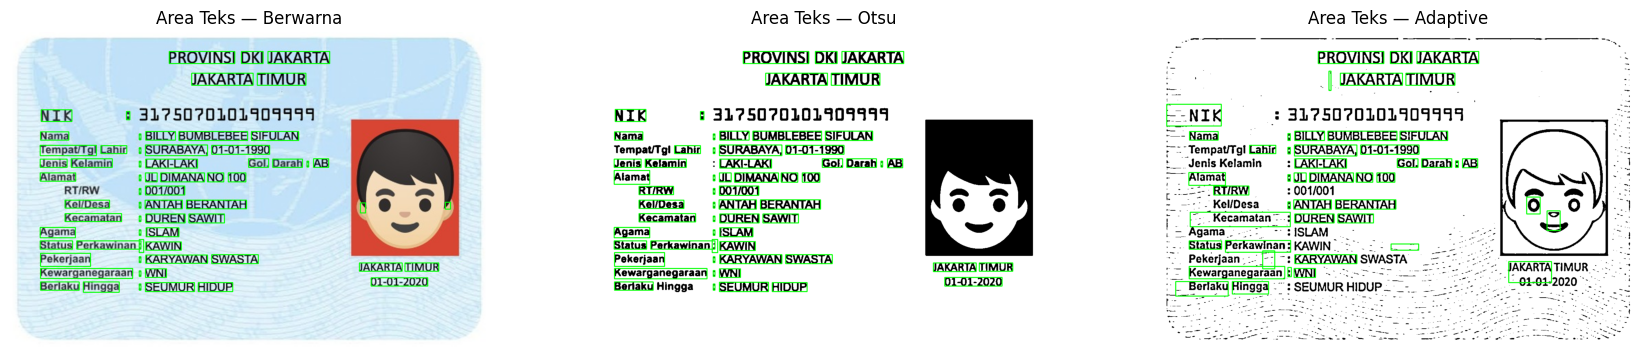

========== BERWARNA ==========
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK : 3175070101901411
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin : LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RT/RW : 001/001

Kel/Desa : ANTAH BERANTAH N 4

Kecamatan : DUREN SAWIT
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020

========== OTSU ==========
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK : 3175070101401111
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin 1 LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RT/RW : 001/001

Kel/Desa : ANTAH BERANTAH

Kecamatan : DUREN SAWIT
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR
Beriaku Hingga” : SEUMUR HIDUP 01-01-2020

========== ADAPTIVE ==========
Sa PROVINSI DKI JAKARTA 3
3 ' . | JAKARTA TIMUR :
—-NIK 3 3175070101909999 5
#

In [13]:
hasil_teks, hasil_data, gambar_kotak = {}, {}, {}

for nama, im in inputs.items():
    # image_to_string
    hasil_teks[nama] = pytesseract.image_to_string(im, lang=LANG, config=CONFIG)

    # image_to_data + kotak hijau (conf > 60)
    d = pytesseract.image_to_data(im, lang=LANG, config=CONFIG, output_type=Output.DICT)
    hasil_data[nama] = d
    canvas = im.copy() if im.ndim == 3 else cv.cvtColor(im, cv.COLOR_GRAY2RGB)
    for i in range(len(d['text'])):
        if d['text'][i].strip() and float(d['conf'][i]) > CONF_MIN:
            x, y, w, h = d['left'][i], d['top'][i], d['width'][i], d['height'][i]
            cv.rectangle(canvas, (x, y), (x + w, y + h), (0, 255, 0), 2)
    gambar_kotak[nama] = canvas

plt.figure(figsize=(21, 5))
for i, (n, im) in enumerate(gambar_kotak.items()):
    plt.subplot(1, 3, i+1); plt.imshow(im); plt.title(f'Area Teks — {n}'); plt.axis('off')
plt.show()

for n, t in hasil_teks.items():
    print(f'========== {n.upper()} ==========')
    print(t)

### 4 & 5. Tabel perbandingan 10 item dan persentase kecocokan
**Ganti `GROUND_TRUTH`** dengan 10 kata/angka yang terlihat jelas pada KTP milik kelompokmu. Item dinyatakan cocok jika seluruh huruf/angka sama dengan acuan (huruf besar-kecil dan spasi awal/akhir diabaikan). Item yang tidak terbaca dihitung tidak cocok.

In [14]:
# 10 acuan sesuai tulisan pada KTP (contoh: KTP Billy Bumblebee Sifulan)
GROUND_TRUTH = ['PROVINSI', 'JAKARTA', '3175070101909999', 'BUMBLEBEE', 'SURABAYA',
                '01-01-1990', 'LAKI-LAKI', 'BERANTAH', 'ISLAM', 'KARYAWAN']

def norm(s):
    return s.strip().strip(',:;.').lower()

def tokens_of(text):
    return [norm(t) for t in re.split(r'\s+', text) if norm(t)]

def cek_item(item, toks):
    """Kembalikan (hasil OCR terdekat, cocok?)"""
    it = norm(item)
    if it in toks:
        return it.upper(), True
    mirip = difflib.get_close_matches(it, toks, n=1, cutoff=0.5)
    return (mirip[0].upper() if mirip else '(tidak terbaca)'), False

rows = []
cocok = {n: 0 for n in inputs}
for no, item in enumerate(GROUND_TRUTH, 1):
    row = {'No.': no, 'Teks sebenarnya': item}
    for n in inputs:
        ocr_item, ok = cek_item(item, tokens_of(hasil_teks[n]))
        row['OCR ' + n] = ocr_item + (' ✓' if ok else ' ✗')
        cocok[n] += ok
    rows.append(row)

tabel = pd.DataFrame(rows)
display(tabel)

# Rata-rata confidence (semua kata yang terbaca, conf >= 0)
def rata_conf(d):
    c = [float(c) for t, c in zip(d['text'], d['conf']) if t.strip() and float(c) >= 0]
    return sum(c) / len(c) if c else 0

ringkasan = pd.DataFrame({
    'Citra masukan OCR': ['Berwarna asli', 'Segmentasi Otsu', 'Segmentasi Adaptive'],
    'Item terbaca tepat': [cocok[n] for n in inputs],
    'Kecocokan (%)': [cocok[n] / len(GROUND_TRUTH) * 100 for n in inputs],
    'Rata-rata confidence': [round(rata_conf(hasil_data[n]), 2) for n in inputs],
})
display(ringkasan)

,No.,Teks sebenarnya,OCR Berwarna,OCR Otsu,OCR Adaptive
0,1,PROVINSI,PROVINSI ✓,PROVINSI ✓,PROVINSI ✓
1,2,JAKARTA,JAKARTA ✓,JAKARTA ✓,JAKARTA ✓
2,3,3175070101909999,3175070101901411 ✗,3175070101401111 ✗,3175070101909999 ✓
3,4,BUMBLEBEE,BUMBLEBEE ✓,BUMBLEBEE ✓,BUMBLEBEE ✓
4,5,SURABAYA,SURABAYA ✓,SURABAYA ✓,SURABAYA ✓
5,6,01-01-1990,01-01-1990 ✓,01-01-1990 ✓,01-01-1990 ✓
6,7,LAKI-LAKI,LAKI-LAKI ✓,LAKI-LAKI ✓,LAKI-LAKI ✓
7,8,BERANTAH,BERANTAH ✓,BERANTAH ✓,BERANTAH ✓
8,9,ISLAM,ISLAM ✓,ISLAM ✓,ISLAM ✓
9,10,KARYAWAN,KARYAWAN ✓,KARYAWAN ✓,KARYAWAN ✓


,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Berwarna asli,9,90.0,89.53
1,Segmentasi Otsu,9,90.0,89.06
2,Segmentasi Adaptive,10,100.0,48.34


### Pertanyaan Analisis
Jalankan sel di bawah untuk bantuan jawaban otomatis, lalu **sesuaikan** jawabannya dengan hasil percobaan kelompokmu.

In [15]:
terbaik = ringkasan.loc[ringkasan['Kecocokan (%)'].idxmax()]
conf_tertinggi = ringkasan.loc[ringkasan['Rata-rata confidence'].idxmax()]

print('1) Citra paling tepat      :', terbaik['Citra masukan OCR'],
      f"({int(terbaik['Item terbaca tepat'])}/10 = {terbaik['Kecocokan (%)']:.0f}%)")

print('\n2) Contoh kesalahan pembacaan (item yang salah/tidak terbaca):')
for _, r in tabel.iterrows():
    for n in inputs:
        if r['OCR ' + n].endswith('✗'):
            print(f"   - [{n}] seharusnya '{r['Teks sebenarnya']}' terbaca '{r['OCR ' + n][:-2]}'")

print('\n5) Confidence tertinggi    :', conf_tertinggi['Citra masukan OCR'],
      '| Kecocokan tertinggi:', terbaik['Citra masukan OCR'],
      '→ sama' if conf_tertinggi['Citra masukan OCR'] == terbaik['Citra masukan OCR'] else '→ BERBEDA')

1) Citra paling tepat      : Segmentasi Adaptive (10/10 = 100%)

2) Contoh kesalahan pembacaan (item yang salah/tidak terbaca):
   - [Berwarna] seharusnya '3175070101909999' terbaca '3175070101901411'
   - [Otsu] seharusnya '3175070101909999' terbaca '3175070101401111'

5) Confidence tertinggi    : Berwarna asli | Kecocokan tertinggi: Segmentasi Adaptive → BERBEDA


**Jawaban :**

1. Citra masukan dengan pembacaan paling tepat adalah segmentasi adaptive

2. Contoh kesalahan: angka NIK sering salah karena font NIK pada KTP berbentuk khusus (misalnya angka `7` terbaca `?` atau `1` terbaca `4`), dan teks kecil seperti *Kel/Desa* dapat terbaca bercampur dengan simbol lain.

3. Segmentasi **tidak selalu** meningkatkan ketepatan OCR. Segmentasi membantu jika latar berpola/berwarna mengganggu tulisan, tetapi jika nilai ambang kurang cocok, huruf tipis bisa putus atau hilang dan noise latar muncul sebagai bintik sehingga hasil OCR justru turun. Jawaban akhir harus mengacu pada perbandingan angka pada tabel ringkasan.

4. Warna atau pola latar (misalnya gelombang halus biru pada KTP) mengurangi kontras antara huruf dan latar sehingga huruf sulit dikenali. Latar yang polos dan kontras tinggi (hitam-putih hasil threshold) memudahkan Tesseract, namun foto/gambar pada KTP ikut berubah menjadi pola hitam-putih yang bisa terbaca sebagai teks palsu.

5. Belum tentu. Confidence hanya menunjukkan keyakinan mesin OCR, bukan kebenaran hasilnya. Bisa saja satu metode memiliki rata-rata confidence tinggi karena hanya membaca sedikit kata yang jelas, tetapi item yang cocok dengan acuan justru lebih sedikit. Bandingkan hasil dua kolom terakhir pada tabel ringkasan.